# Autoencoders

In [15]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import keras.datasets.mnist as mnist
from keras.models import Sequential
from keras.layers import Dense, Flatten, Reshape, Dropout

In [16]:
# Dataset
(input_train, _), (input_test, _) = mnist.load_data()

In [17]:
input_train.shape, input_test.shape

((60000, 28, 28), (10000, 28, 28))

In [18]:
input_train[0]

array([[  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   3,
         18,  18,  18, 126, 136, 175,  26, 166, 255, 247, 127,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,  30,  36,  94, 154, 170,
        253, 253, 253, 253, 253, 225, 172, 253, 242, 195,  64,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,  49, 238, 253, 253, 253, 253,
        253, 253, 253, 253, 251,  93,  82,  82,  56,  39,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,  18, 219, 253, 253, 253, 253,
        253, 198, 182, 247, 241,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,  80, 156, 107, 253, 253,
        205,  11,   0,  43, 154,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,  14,   1, 154, 253,
         90,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0, 139, 253,
        190,   2,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,  11, 190,
        253,  70,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,  35,
        241, 225, 160, 108,   1,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
         81, 240, 253, 253, 119,  25,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,  45, 186, 253, 253, 150,  27,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,  16,  93, 252, 253, 187,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0, 249, 253, 249,  64,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,  46, 130, 183, 253, 253, 207,   2,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,  39,
        148, 229, 253, 253, 253, 250, 182,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,  24, 114, 221,
        253, 253, 253, 253, 201,  78,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,  23,  66, 213, 253, 253,
        253, 253, 198,  81,   2,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,  18, 171, 219, 253, 253, 253, 253,
        195,  80,   9,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,  55, 172, 226, 253, 253, 253, 253, 244, 133,
         11,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0, 136, 253, 25

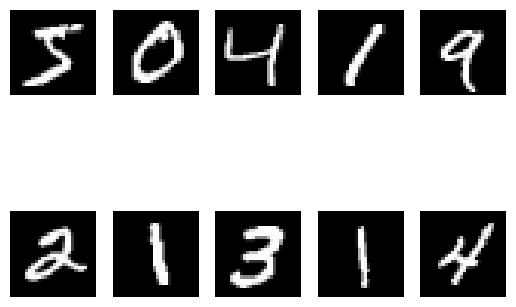

In [19]:
for i in range(10):
    plt.subplot(2, 5, i+1)
    plt.imshow(input_train[i], cmap='gray')
    plt.axis('off')

In [20]:
# Reshape
input_train = input_train.reshape((input_train.shape[0], -1))
input_test = input_test.reshape((input_test.shape[0], -1))
input_train.shape, input_test.shape

((60000, 784), (10000, 784))

In [21]:
# Normalization
input_train = input_train / 255
input_test = input_test / 255

In [22]:
# Autoencoder
def build_autoencoder(latent_features, input_shape=784):
  model = Sequential()

  # Encoder
  model.add(Dense(256, activation='relu', input_shape=(input_shape,)))
  model.add(Dense(64, activation='relu'))

  # Code
  model.add(Dense(latent_features, activation='relu'))

  # Decoder
  model.add(Dense(64, activation='relu'))
  model.add(Dense(256, activation='relu'))

  model.add(Dense(input_shape, activation='sigmoid'))

  # Compile
  model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

  return model



In [23]:
# # Autoencoder
# def build_autoencoder(latent_features, input_shape=784):
#   model = Sequential()

#   # Encoder
#   model.add(Dense(256, activation='relu', input_shape=(input_shape,)))
#   model.add(Dense(64, activation='relu'))

#   # Code
#   model.add(Dense(latent_features, activation='relu'))

#   # Decoder
#   model.add(Dense(64, activation='relu'))
#   model.add(Dense(256, activation='relu'))

#   model.add(Dense(input_shape)) # Linear activation

#   # Compile
#   model.compile(optimizer='adam', loss='mse', metrics=['mae'])

#   return model



In [24]:
# Train AE
latent_features = 8
epochs = 20
batch_size = 128

autoencoder = build_autoencoder(latent_features, input_train.shape[1])
autoencoder.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_6 (Dense)                 │ (None, 256)            │       200,960 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 64)             │        16,448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 8)              │           520 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 64)             │           576 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 256)            │        16,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 784)            │       201,488 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 436,632 (1.67 MB)

 Trainable params: 436,632 (1.67 MB)

 Non-trainable params: 0 (0.00 B)

In [25]:
history = autoencoder.fit(input_train,
                          input_train,
                          epochs=epochs,
                          batch_size=batch_size,
                          validation_split=0.2,
                          verbose=True)

Epoch 1/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 6s 8ms/step - accuracy: 0.0127 - loss: 0.2213 - val_accuracy: 0.0129 - val_loss: 0.1635
Epoch 2/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.0116 - loss: 0.1555 - val_accuracy: 0.0076 - val_loss: 0.1508
Epoch 3/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.0111 - loss: 0.1473 - val_accuracy: 0.0131 - val_loss: 0.1454
Epoch 4/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.0101 - loss: 0.1430 - val_accuracy: 0.0149 - val_loss: 0.1424
Epoch 5/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.0111 - loss: 0.1401 - val_accuracy: 0.0103 - val_loss: 0.1397
Epoch 6/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.0101 - loss: 0.1380 - val_accuracy: 0.0117 - val_loss: 0.1378
Epoch 7/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.0115 - loss: 0.1363 - val_accuracy: 0.0121 - val_loss: 0.1366
Epoch 8/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.0109 - loss: 0.1348 - val_accuracy: 0.

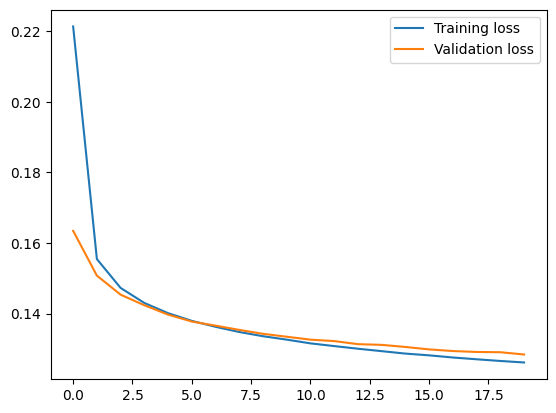

In [26]:
plt.plot(history.history['loss'], label='Training loss')
plt.plot(history.history['val_loss'], label='Validation loss')
plt.legend()

In [27]:
# Visualization
decoded_image = autoencoder.predict(input_test)

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step


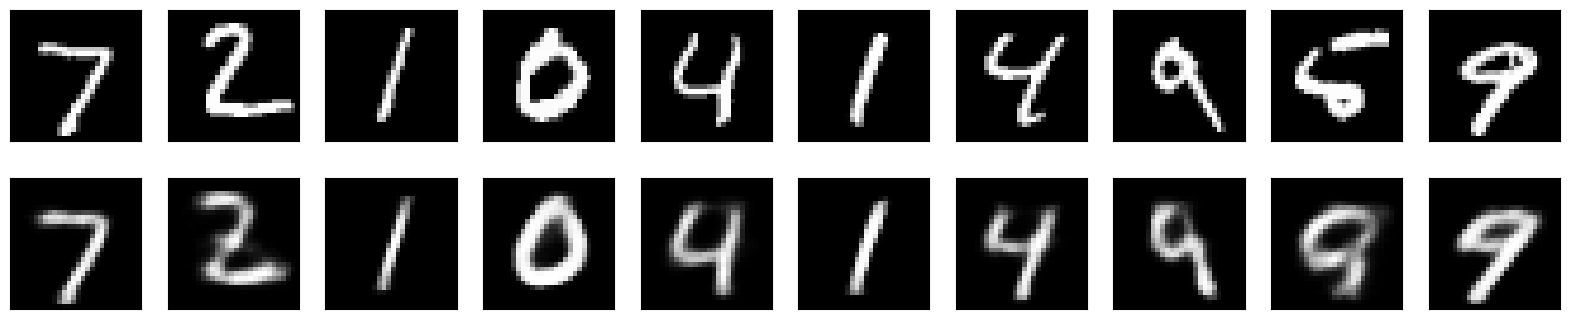

In [28]:
n = 10
plt.figure(figsize=(20, 4))

for i in range(n):
  # Display Original Test Data
  ax = plt.subplot(2, n, i+1)
  plt.imshow(input_test[i].reshape(28, 28))
  plt.gray()
  ax.get_xaxis().set_visible(False)
  ax.get_yaxis().set_visible(False)

  # Display Reconstructed Test Image
  ax = plt.subplot(2, n, i+1+n)
  plt.imshow(decoded_image[i].reshape(28, 28))
  plt.gray()
  ax.get_xaxis().set_visible(False)
  ax.get_yaxis().set_visible(False)

plt.show()